# Day 2 – Predicting Ticket Resolution Time at NetCore TAC

`[C01]` **Can we predict, at triage, how many hours a ticket will take?**

- **Today:** fixed ETAs per severity (S1 4 h, S2 1 day, S3 2 days, S4 3 days); customers say they're unreliable.
- **Goal:** predict resolution hours when the ticket is triaged.
- **Success:** beat "quote the average for every ticket", measured as the average miss in hours (MAE).

**Plan:** Part 0 Foundations · Part 1 Data Quality · Part 2 EDA · Part 3 Features · Part 4 Linear Regression

`[C02]` **Glossary** (all the terms we use today)

| Term | Meaning |
|---|---|
| Machine learning (ML) | Computer learns rules from past examples |
| Model | The learned rules, used to predict |
| Feature | An input column (e.g. severity) |
| Target | What we predict: `resolution_hours` |
| Training / test set | Tickets to learn from / unseen tickets to measure on |
| Data leakage | Using information not known at prediction time |
| Baseline | Simplest prediction to beat: the average |
| Median | Middle value; not pulled by extremes |
| Outlier | A value far from the rest |
| Correlation | How strongly two numbers move together (−1 to +1) |
| One-hot encoding | One yes/no column per category |
| Scaling | Putting numbers on the same yardstick |
| Pipeline | All preparation steps as one recipe |
| Linear regression | Best straight-line fit of the target on the inputs |
| Coefficient | Hours one input adds or removes |
| MAE | Average miss, in hours |
| RMSE | Average miss that punishes big misses |
| R² | Share of variation explained (0 = no better than average) |

`[C03]` **Setup.** Load the libraries and print versions so everyone runs the same setup.

In [1]:
# [C03]
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

for name, lib in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scikit-learn", sklearn)]:
    print(f"{name:<13} {lib.__version__}")

pandas        3.1.1
numpy         2.5.5
matplotlib    3.11.2
seaborn       0.13.2
scikit-learn  1.9.1


`[C04]` **Load the ticket export** into `raw_df`. We never change `raw_df`; every step works on a copy.

In [2]:
# [C04]
from pathlib import Path

# Works from notebooks/ or from the repository root
candidates = [Path("../data/netcore_tickets.csv"), Path("data/netcore_tickets.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Run first: uv run python scripts/generate_tickets.py")

raw_df = pd.read_csv(data_path, parse_dates=["created_at"])
print(f"Loaded {len(raw_df):,} tickets with {raw_df.shape[1]} columns")

Loaded 5,000 tickets with 18 columns


# Part 0 – ML Foundations

## 1. Today's Case and the ML Problem

`[C05]` | | NetCore TAC |
|---|---|
| **Business problem** | Customers say our ETAs are unreliable |
| **Target** | `resolution_hours` |
| **Inputs** | product, severity, tier, region, channel, devices, software age, prior tickets (90 days), engineer experience, first-response minutes |
| **Prediction moment** | At triage |
| **Metric** | MAE in hours, vs quoting the average |

## 2. How Machine Learning Learns

`[C06]` - **Rules vs ML:** traditional code = rules + data → answers. ML = data + answers → rules (the **model**).
- **Regression** predicts a number (hours). **Classification** predicts a category (will it breach SLA?).
- **Today:** regression. Day 3: classification.

## 3. Train/Test Split and Data Leakage

`[C07]` - Learn on **training** tickets; measure on unseen **test** tickets.
- **Leakage** = using information not known at triage. These columns are never inputs:

| Column | Why unknown at triage |
|---|---|
| `resolution_code` | Filled in at closure |
| `escalation_count` | Builds up while the ticket is worked |
| `reopened` | Only after the ticket closed once |
| `sla_breached` | Calculated from the final hours |

## 4. First Mini Demo

`[C08]` Three numeric inputs, tickets with blanks dropped, 80/20 split. `random_state=42` makes the split repeatable.

In [3]:
# [C08]
from sklearn.model_selection import train_test_split

demo_inputs = ["devices_affected", "software_version_months", "engineer_experience_years"]
demo_df = raw_df[demo_inputs + ["resolution_hours"]].dropna().copy()   # copy; drop blanks

X_train, X_test, y_train, y_test = train_test_split(
    demo_df[demo_inputs], demo_df["resolution_hours"], test_size=0.2, random_state=42)
print(f"{len(demo_df):,} tickets kept | train {len(X_train):,} | test {len(X_test):,}")

4,752 tickets kept | train 3,801 | test 951


`[C09]` **Baseline:** quote the training average for every ticket. This is the bar to beat.

In [4]:
# [C09]
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)   # always the training average
baseline_mae = mean_absolute_error(y_test, baseline.predict(X_test))
print(f"Quoting {y_train.mean():.1f} h for every ticket misses by {baseline_mae:.1f} h on average.")

Quoting 55.8 h for every ticket misses by 61.2 h on average.


`[C10]` **Linear regression** on the same three inputs: same `fit` → `predict` → measure pattern.

In [5]:
# [C10]
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)
model_mae = mean_absolute_error(y_test, model.predict(X_test))
print(f"Linear regression misses by {model_mae:.1f} h: {baseline_mae - model_mae:.1f} h better "
      f"than the baseline. Messy data, tiny gain: we clean next.")

Linear regression misses by 61.1 h: 0.2 h better than the baseline. Messy data, tiny gain: we clean next.


# Part 1 – Data Quality

## 5. Getting to Know the Data

`[C11]` First five tickets: one row per ticket, one column per field.

In [6]:
# [C11]
raw_df.head(5)

,ticket_id,created_at,product_family,severity,customer_tier,region,channel,devices_affected,software_version_months,prior_tickets_90d,engineer_experience_years,first_response_minutes,customer_comments,escalation_count,reopened,resolution_code,sla_breached,resolution_hours
0,TKT-000001,2025-01-01 08:06:32,Routers,S4,Platinum,EMEA,Email,1,0,2,6.9,123.0,The Routers shows hardware alarms and a failed...,1,False,Software Bug,False,34.7
1,TKT-000002,2025-01-01 09:44:59,Switches,S3,Gold,APJC,Portal,4,54,1,7.6,29.2,Intermittent latency spikes observed on the Sw...,1,False,Software Bug,True,70.4
2,TKT-000003,2025-01-01 10:43:58,Switches,S2,Gold,AMER,Phone,2,23,3,5.5,37.4,Need urgent help: Switches outage impacting mu...,0,False,Hardware RMA,True,35.1
3,TKT-000004,2025-01-01 11:11:45,SD-WAN,S3,Silver,APJC,Phone,1,24,1,2.4,128.5,The SD-WAN shows hardware alarms and a failed ...,1,False,Customer Environment,False,33.7
4,TKT-000005,2025-01-01 11:32:37,Routers,S3,Silver,AMER,Portal,5,15,0,3.6,70.4,Our Routers rebooted unexpectedly during busin...,2,True,Hardware RMA,True,131.7


`[C12]` **Today's business metrics** from the raw export: MTTR (mean and median) and SLA breach rate.

In [7]:
# [C12]
print(f"Tickets        : {len(raw_df):,}")
print(f"MTTR (mean)    : {raw_df['resolution_hours'].mean():.1f} h")
print(f"MTTR (median)  : {raw_df['resolution_hours'].median():.1f} h")
print(f"SLA breach rate: {raw_df['sla_breached'].mean():.1%}")   # True = 1, False = 0

Tickets        : 5,000
MTTR (mean)    : 58.8 h
MTTR (median)  : 28.9 h
SLA breach rate: 28.1%


## 6. Finding and Fixing What's Broken

`[C13]` **Blank fields** per column, on a working copy `dq_df`.

In [8]:
# [C13]
dq_df = raw_df.copy()   # working copy; raw_df is never modified

missing = dq_df.isna().sum()
missing = missing[missing > 0]
pd.DataFrame({"blank_tickets": missing, "blank_pct": (missing / len(dq_df) * 100).round(1)})

,blank_tickets,blank_pct
severity,50,1.0
engineer_experience_years,248,5.0
first_response_minutes,251,5.0


`[C14]` **Messy labels:** "Sev-1", "SEV1", "s1" → "S1"; " emea " → "EMEA".

In [9]:
# [C14]
bad_sev = dq_df["severity"].notna() & ~dq_df["severity"].isin(["S1", "S2", "S3", "S4"])
bad_region = ~dq_df["region"].isin(["AMER", "EMEA", "APJC"])

dq_df["severity"] = (dq_df["severity"].str.upper()   # "Sev-1" -> "SEV-1" -> "S1"
                     .str.replace("EV", "").str.replace(" ", "").str.replace("-", ""))
dq_df["region"] = dq_df["region"].str.strip().str.upper()   # " emea " -> "EMEA"

print(f"Fixed {bad_sev.sum()} severity and {bad_region.sum()} region labels")
print("Severity:", sorted(dq_df["severity"].dropna().unique()), "| Region:", sorted(dq_df["region"].unique()))

Fixed 149 severity and 147 region labels
Severity: ['S1', 'S2', 'S3', 'S4'] | Region: ['AMER', 'APJC', 'EMEA']


`[C15]` **Impossible values:** a negative response time can't happen, so we blank it (filled later with the rest).

In [10]:
# [C15]
negative = dq_df["first_response_minutes"] < 0
dq_df.loc[negative, "first_response_minutes"] = np.nan   # unknown true value -> blank

print(f"Blanked {negative.sum()} negative response times; "
      f"blank response times now: {dq_df['first_response_minutes'].isna().sum()}")

Blanked 10 negative response times; blank response times now: 261


`[C16]` **Duplicates:** same ticket logged twice. Every field matches except ID, channel and time. Keep the first.

In [11]:
# [C16]
# A duplicate matches on every field except ticket ID, channel and created time
match_cols = [c for c in dq_df.columns if c not in ["ticket_id", "channel", "created_at"]]
is_duplicate = dq_df.sort_values("created_at").duplicated(subset=match_cols, keep="first")

dq_df = dq_df.drop(index=is_duplicate[is_duplicate].index)
print(f"Removed {is_duplicate.sum()} duplicate tickets -> {len(dq_df):,} left")

Removed 100 duplicate tickets -> 4,900 left


## 7. Mean or Median for the Gaps

`[C17]` **Mean or median** to fill the gaps? The histogram shows mean and median for first-response time.

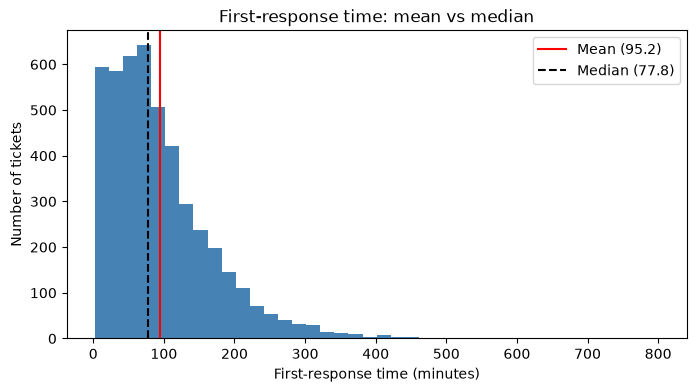

In [12]:
# [C17]
response = dq_df["first_response_minutes"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(response, bins=40, color="steelblue")
ax.axvline(response.mean(), color="red", label=f"Mean ({response.mean():.1f})")
ax.axvline(response.median(), color="black", linestyle="--", label=f"Median ({response.median():.1f})")
ax.set_title("First-response time: mean vs median")
ax.set_xlabel("First-response time (minutes)")
ax.set_ylabel("Number of tickets")
ax.legend()
plt.show()

`[C18]` **What to notice**
- Long tail to the right: the mean is pulled above the median.
- The **median** is the safer fill-in. Filling happens in Part 3, from training tickets only.

## 8. Extreme Tickets

`[C19]` **Box plot** of resolution hours: the box is the middle half of tickets; dots are far from the rest.

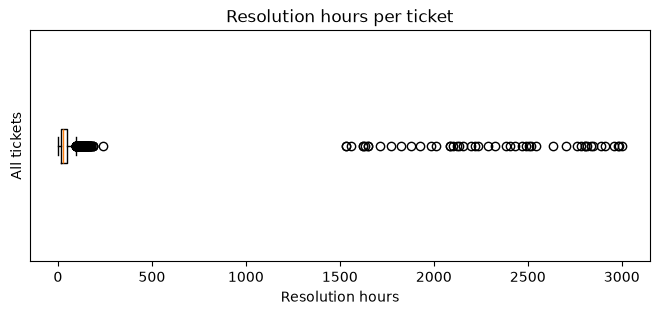

In [13]:
# [C19]
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(dq_df["resolution_hours"], orientation="horizontal")
ax.set_title("Resolution hours per ticket")
ax.set_xlabel("Resolution hours")
ax.set_ylabel("All tickets")
ax.set_yticks([])   # a single box needs no tick labels
plt.show()

`[C20]` **What to notice**
- Typical tickets take tens of hours; the box is squeezed against the left.
- A separate cluster sits at about 1,500–3,000 hours: weeks to months.

`[C21]` **IQR rule vs business rule:** how many tickets does each flag?

In [14]:
# [C21]
q1, q3 = dq_df["resolution_hours"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)   # the box plot's whisker limit

print(f"Q1 = {q1:.1f} h, Q3 = {q3:.1f} h, upper fence = {upper_fence:.1f} h")
print(f"Above the fence : {(dq_df['resolution_hours'] > upper_fence).sum()} tickets")
print(f"Above 1,000 h   : {(dq_df['resolution_hours'] > 1000).sum()} tickets")

Q1 = 18.2 h, Q3 = 49.3 h, upper fence = 95.9 h
Above the fence : 229 tickets
Above 1,000 h   : 49 tickets


`[C22]` **Remove the parked RMA tickets** (over 1,000 h) → `clean_df`. We look at their resolution code only to understand them.

In [15]:
# [C22]
extreme = dq_df["resolution_hours"] > 1000
print(dq_df.loc[extreme, "resolution_code"].value_counts().to_string())   # look only, not an input

clean_df = dq_df[~extreme].copy()
print(f"Removed {extreme.sum()} parked RMA tickets -> {len(clean_df):,} left; "
      f"longest now {clean_df['resolution_hours'].max():.1f} h")

resolution_code
Hardware RMA    49
Removed 49 parked RMA tickets -> 4,851 left; longest now 237.4 h


`[C23]` **Business metrics:** raw export vs cleaned tickets.

In [16]:
# [C23]
def business_metrics(df):
    return [len(df), df["resolution_hours"].mean(), df["resolution_hours"].median(),
            df["sla_breached"].mean() * 100]

pd.DataFrame({"raw export": business_metrics(raw_df), "cleaned": business_metrics(clean_df)},
             index=["tickets", "MTTR mean (h)", "MTTR median (h)", "SLA breach rate (%)"]).round(1)

,raw export,cleaned
tickets,5000.0,4851.0
MTTR mean (h),58.8,36.7
MTTR median (h),28.9,28.6
SLA breach rate (%),28.1,27.3


# Part 2 – Exploratory Data Analysis

## 9. What Makes a Ticket Slow

`[C24]` **Distribution** of resolution hours, with mean and median.

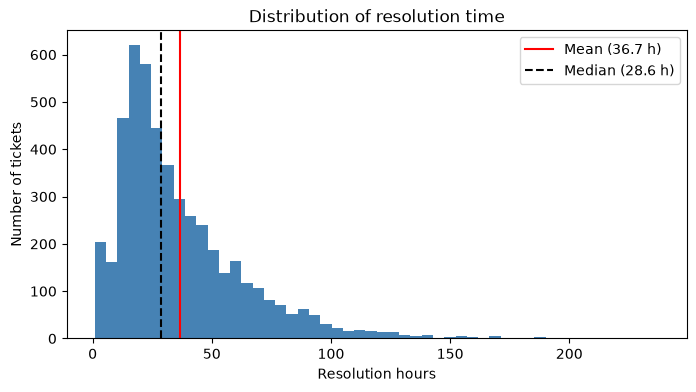

In [17]:
# [C24]
hours = clean_df["resolution_hours"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(hours, bins=50, color="steelblue")
ax.axvline(hours.mean(), color="red", label=f"Mean ({hours.mean():.1f} h)")
ax.axvline(hours.median(), color="black", linestyle="--", label=f"Median ({hours.median():.1f} h)")
ax.set_title("Distribution of resolution time")
ax.set_xlabel("Resolution hours")
ax.set_ylabel("Number of tickets")
ax.legend()
plt.show()

`[C25]` **What to notice**
- Most tickets close in one or two days, with a long tail.
- The **median** describes a typical ticket better than the mean.

`[C26]` **Median hours and SLA breach rate** by severity, customer tier and engineer experience.

In [18]:
# [C26]
experience_band = pd.cut(clean_df["engineer_experience_years"], bins=[0, 3, 8, 20],
                         labels=["0-3 yrs", "3-8 yrs", "8+ yrs"])   # temporary bands
parts = []
for name, groups in [("severity", clean_df["severity"]), ("tier", clean_df["customer_tier"]),
                     ("experience", experience_band)]:
    summary = clean_df.groupby(groups, observed=True).agg(
        median_hours=("resolution_hours", "median"), breach_pct=("sla_breached", "mean"))
    parts.append(summary.set_axis([f"{name}: {g}" for g in summary.index]))
table = pd.concat(parts)
table.assign(breach_pct=table["breach_pct"] * 100).round(1)

,median_hours,breach_pct
severity: S1,2.3,25.6
severity: S2,23.6,49.4
severity: S3,27.8,23.9
severity: S4,37.6,18.3
tier: Gold,28.4,27.2
tier: Platinum,24.4,22.0
tier: Silver,30.7,29.9
experience: 0-3 yrs,33.1,34.4
experience: 3-8 yrs,30.4,30.7
experience: 8+ yrs,23.6,18.9


`[C27]` **Correlation** of each numeric column with resolution hours. Leakage columns in red.

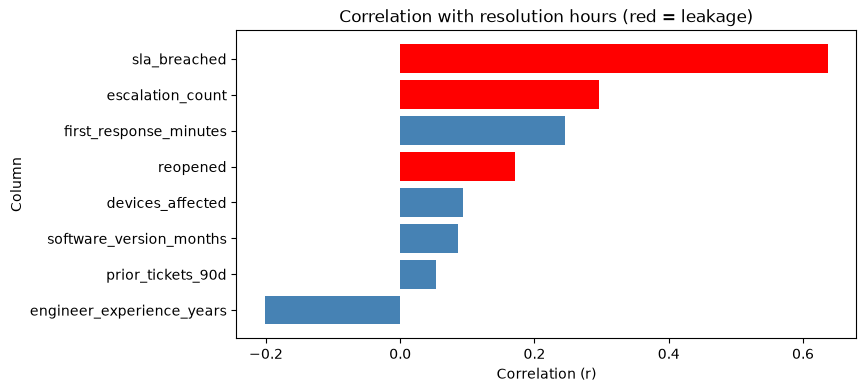

In [19]:
# [C27]
corr_cols = ["devices_affected", "software_version_months", "prior_tickets_90d",
             "engineer_experience_years", "first_response_minutes",
             "escalation_count", "reopened", "sla_breached"]
corr = clean_df[corr_cols].astype(float).corrwith(clean_df["resolution_hours"]).sort_values()
leakage_cols = ["resolution_code", "escalation_count", "reopened", "sla_breached"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr.index, corr.values, color=["red" if c in leakage_cols else "steelblue" for c in corr.index])
ax.set_title("Correlation with resolution hours (red = leakage)")
ax.set_xlabel("Correlation (r)")
ax.set_ylabel("Column")
plt.show()

`[C28]` **What to notice**
- The two longest bars are **red**: known only after triage, never inputs.
- Experience pulls hours down; severity (table above) is the biggest driver.

# Part 3 – Feature Engineering

## 10. Choosing Inputs and Splitting

`[C29]` **Two TAC flags:** opened at the weekend, software older than 3 years. Row by row, nothing learned → no leakage.

In [20]:
# [C29]
def add_tac_features(df):
    """Add the is_weekend and old_software flags (0/1); drop created_at."""
    df = df.copy()   # never change the caller's data
    df["is_weekend"] = (df["created_at"].dt.day_of_week >= 5).astype(int)   # 5 = Sat, 6 = Sun
    df["old_software"] = (df["software_version_months"] > 36).astype(int)  # older than 3 years
    return df.drop(columns="created_at")

`[C30]` **Inputs and split:** triage fields only (no leakage, no ID, no comment), then 80/20.

In [21]:
# [C30]
numeric_features = ["devices_affected", "software_version_months", "prior_tickets_90d",
                    "engineer_experience_years", "first_response_minutes"]
flag_features = ["is_weekend", "old_software"]
categorical_features = ["product_family", "severity", "customer_tier", "region", "channel"]

X = add_tac_features(clean_df)[numeric_features + flag_features + categorical_features]
y = clean_df["resolution_hours"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training tickets: {len(X_train):,} | Test tickets: {len(X_test):,}")

Training tickets: 3,880 | Test tickets: 971


## 11. Turning Categories into Numbers

`[C31]` **One-hot encoding:** each product becomes its own yes/no column. Then a product we've never seen.

In [22]:
# [C31]
from sklearn.preprocessing import OneHotEncoder

# handle_unknown="ignore": an unseen product gets all zeros instead of an error
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[["product_family"]])

sample = pd.DataFrame({"product_family": ["Firewalls", "Routers", "Optical Transport"]})
pd.DataFrame(encoder.transform(sample), columns=encoder.get_feature_names_out(),
             index=sample["product_family"]).astype(int)

,product_family_Firewalls,product_family_Routers,product_family_SD-WAN,product_family_Switches,product_family_Wireless
product_family,,,,,
Firewalls,1,0,0,0,0
Routers,0,1,0,0,0
Optical Transport,0,0,0,0,0


## 12. Scaling and TAC Flags

`[C32]` **Scaling** (inside the pipeline) puts every number on the same yardstick. Here: do the two flags matter?

In [23]:
# [C32]
for flag in flag_features:
    medians = y_train.groupby(X_train[flag]).median()   # training tickets only
    print(f"{flag:<13} | flag=0: {medians[0]:.1f} h | flag=1: {medians[1]:.1f} h "
          f"| {X_train[flag].mean():.0%} of tickets have it")

is_weekend    | flag=0: 28.5 h | flag=1: 27.4 h | 10% of tickets have it
old_software  | flag=0: 27.7 h | flag=1: 29.5 h | 40% of tickets have it


## 13. One Recipe for Every Ticket

`[C33]` **Two small recipes:** numbers (fill with median → scale) and categories (fill with most common → one-hot).

In [24]:
# [C33]
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_pipe = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
category_pipe = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

`[C34]` **One recipe:** `ColumnTransformer` sends numbers, flags (kept as 0/1) and categories to their own steps.

In [25]:
# [C34]
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([("num", numeric_pipe, numeric_features),
                                  ("flags", "passthrough", flag_features),   # keep 0/1 as is
                                  ("cat", category_pipe, categorical_features)],
                                 verbose_feature_names_out=False)   # short column names
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('flags', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transform

`[C35]` **Learn from training tickets only** (`fit_transform`), then only apply to test tickets (`transform`).

In [26]:
# [C35]
X_train_prepared = preprocessor.fit_transform(X_train)   # learn + apply (training only)
X_test_prepared = preprocessor.transform(X_test)         # apply only

feature_names = preprocessor.get_feature_names_out()
print(f"{len(feature_names)} model-ready columns | train {X_train_prepared.shape[0]:,} rows "
      f"| test {X_test_prepared.shape[0]:,} rows | blanks left: {int(np.isnan(X_train_prepared).sum())}")

25 model-ready columns | train 3,880 rows | test 971 rows | blanks left: 0


`[C36]` **Tomorrow's ticket:** opened Saturday, unseen product, engineer experience still blank. Same recipe.

In [27]:
# [C36]
new_ticket = pd.DataFrame([{
    "devices_affected": 4, "software_version_months": 40, "prior_tickets_90d": 1,
    "engineer_experience_years": np.nan, "first_response_minutes": 20.0,
    "product_family": "Optical Transport", "severity": "S2", "customer_tier": "Gold",
    "region": "EMEA", "channel": "Phone", "created_at": pd.Timestamp("2026-11-21 10:00"),  # a Saturday
}])
prepared = pd.DataFrame(preprocessor.transform(add_tac_features(new_ticket)), columns=feature_names)
prepared[["engineer_experience_years", "is_weekend", "old_software",
          "product_family_Firewalls", "product_family_Routers", "severity_S2"]].round(2)

,engineer_experience_years,is_weekend,old_software,product_family_Firewalls,product_family_Routers,severity_S2
0,-0.23,1.0,1.0,0.0,0.0,1.0


# Part 4 – Linear Regression

## 14. Baseline and the Best Line

`[C37]` **Baseline:** quote the training average for every ticket.

In [28]:
# [C37]
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)   # the training average
baseline_pred = baseline.predict(X_test)
print(f"Baseline ETA: {y_train.mean():.1f} h for every ticket; "
      f"MAE {mean_absolute_error(y_test, baseline_pred):.1f} h")

Baseline ETA: 36.6 h for every ticket; MAE 20.5 h


`[C38]` **Best straight line** using devices affected only: hours = intercept + slope × devices.

In [29]:
# [C38]
simple_model = LinearRegression().fit(X_train[["devices_affected"]], y_train)
simple_pred = simple_model.predict(X_test[["devices_affected"]])

slope, intercept = simple_model.coef_[0], simple_model.intercept_
print(f"Predicted hours = {intercept:.1f} + {slope:.2f} x devices affected")
print(f"In plain words: each extra device adds about {slope:.1f} hours.")

Predicted hours = 34.3 + 0.93 x devices affected
In plain words: each extra device adds about 0.9 hours.


`[C39]` **The line** drawn over the test tickets.

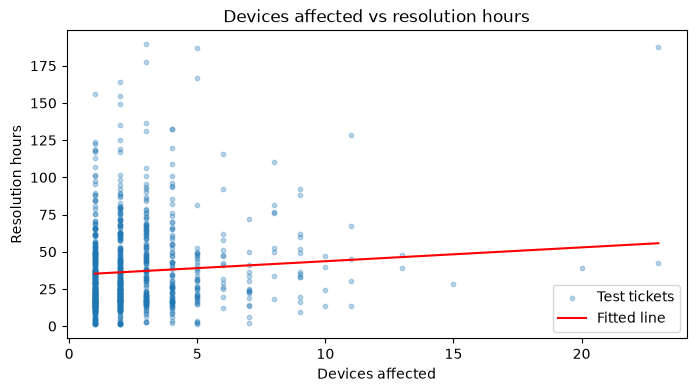

In [30]:
# [C39]
devices = np.arange(1, X_test["devices_affected"].max() + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_test["devices_affected"], y_test, alpha=0.3, s=10, label="Test tickets")
ax.plot(devices, intercept + slope * devices, color="red", label="Fitted line")
ax.set_title("Devices affected vs resolution hours")
ax.set_xlabel("Devices affected")
ax.set_ylabel("Resolution hours")
ax.legend()
plt.show()

`[C40]` **What to notice**
- Gentle slope: devices have a small effect.
- Wide spread around the line: devices alone can't give a good ETA.

`[C41]` **Actual vs predicted** for five test tickets. Error = actual − predicted.

In [31]:
# [C41]
five = pd.DataFrame({"devices_affected": X_test["devices_affected"].head(5),
                     "actual_hours": y_test.head(5),
                     "predicted_hours": simple_pred[:5]})
five["error_hours"] = five["actual_hours"] - five["predicted_hours"]   # + = took longer
five.round(1)

,devices_affected,actual_hours,predicted_hours,error_hours
3316,1,61.8,35.3,26.5
1745,2,78.3,36.2,42.1
1083,1,52.9,35.3,17.6
4959,2,29.3,36.2,-6.9
1594,1,20.7,35.3,-14.6


## 15. Many Factors at Once

`[C42]` **Full model:** the recipe from section 13 + linear regression, trained on training tickets.

In [32]:
# [C42]
full_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
full_model.fit(X_train, y_train)          # learns preparation AND model from training tickets
full_pred = full_model.predict(X_test)    # same recipe applied to unseen tickets
print(f"Trained on {len(X_train):,} tickets with {len(feature_names)} prepared inputs")

Trained on 3,880 tickets with 25 prepared inputs


`[C43]` **Coefficients:** hours each prepared input adds (right) or removes (left).

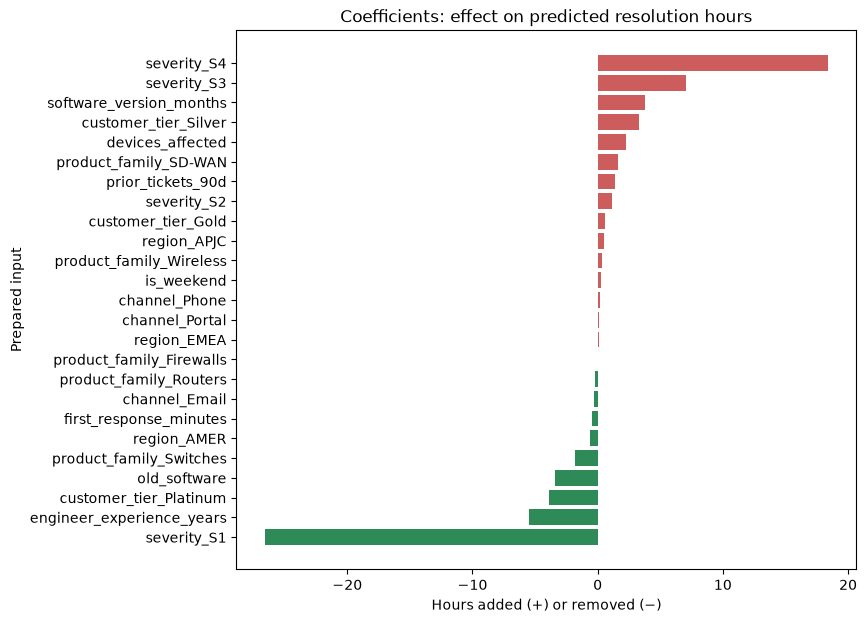

In [33]:
# [C43]
coefs = pd.Series(full_model.named_steps["model"].coef_, index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefs.index, coefs.values, color=["seagreen" if v < 0 else "indianred" for v in coefs.values])
ax.set_title("Coefficients: effect on predicted resolution hours")
ax.set_xlabel("Hours added (+) or removed (−)")
ax.set_ylabel("Prepared input")
plt.show()

`[C44]` **What to notice**
- Severity dominates; experience and Platinum tier pull hours down.
- Region, channel and first-response time are close to zero.

## 16. How Far Off Are Our ETAs

`[C45]` **MAE, RMSE and R²** for the baseline, the devices-only line and the full model, on unseen test tickets.

In [34]:
# [C45]
from sklearn.metrics import mean_squared_error, r2_score

predictions = {"Baseline": baseline_pred, "Devices only": simple_pred, "All triage fields": full_pred}
results = pd.DataFrame({name: {"MAE (h)": mean_absolute_error(y_test, p),
                               "RMSE (h)": np.sqrt(mean_squared_error(y_test, p)),
                               "R²": r2_score(y_test, p)}
                        for name, p in predictions.items()}).T
results.round(2)

,MAE (h),RMSE (h),R²
Baseline,20.46,27.97,-0.00
Devices only,20.33,27.74,0.02
All triage fields,18.47,25.04,0.20


`[C46]` **Scorecard chart:** MAE and RMSE per model; shorter is better.

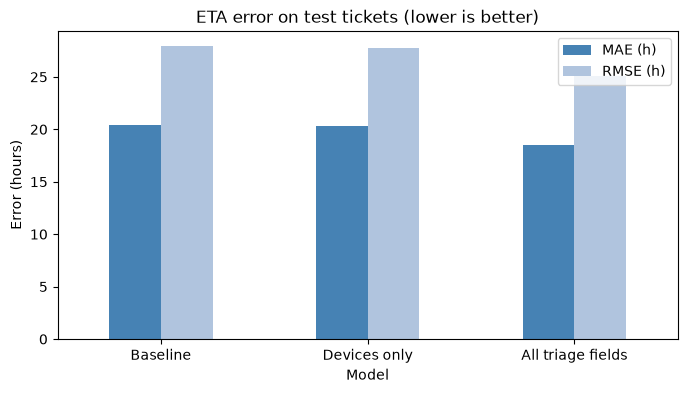

In [35]:
# [C46]
fig, ax = plt.subplots(figsize=(8, 4))
results[["MAE (h)", "RMSE (h)"]].plot.bar(ax=ax, color=["steelblue", "lightsteelblue"], rot=0)
ax.set_title("ETA error on test tickets (lower is better)")
ax.set_xlabel("Model")
ax.set_ylabel("Error (hours)")
plt.show()

`[C47]` **What to notice**
- The full model has the shortest bars, but the gain is **modest**.
- RMSE > MAE: some tickets are still missed by a lot.

`[C48]` **In plain hours:** the scorecard as sentences for a TAC manager.

In [36]:
# [C48]
base, full = results.loc["Baseline"], results.loc["All triage fields"]
gain = base["MAE (h)"] - full["MAE (h)"]
print(f"MAE : the average misses by {base['MAE (h)']:.1f} h, our model by {full['MAE (h)']:.1f} h "
      f"({gain:.1f} h, {gain / base['MAE (h)']:.0%} better per ticket).")
print(f"RMSE: {full['RMSE (h)']:.1f} h vs {base['RMSE (h)']:.1f} h: big misses shrink too.")
print(f"R²  : {full['R²']:.2f}: we explain about {full['R²']:.0%} of the ticket-to-ticket variation.")

MAE : the average misses by 20.5 h, our model by 18.5 h (2.0 h, 10% better per ticket).
RMSE: 25.0 h vs 28.0 h: big misses shrink too.
R²  : 0.20: we explain about 20% of the ticket-to-ticket variation.


## Summary for NetCore Support Leadership

`[C49]` - **Better ETAs:** average miss **20.5 h → 18.5 h** (2.0 h, 10% better). Real but modest.
- **Top 3 drivers:**
  1. **Severity:** S1 median 2.3 h vs S4 37.6 h.
  2. **Engineer experience:** 8+ years 23.6 h vs 0–3 years 33.1 h.
  3. **Customer tier:** Platinum 24.4 h vs Silver 30.7 h.
- **Little difference:** region, channel, product.
- **Next steps:** capture an early "suspected hardware / bug" field at triage · pilot on S2 (49% breach) · route complex tickets to senior engineers · Day 3: predict SLA breach (classification).